# Lecture 11: Requirements and Architectures for Quantum Computers

[Course contents](../00_course_contents.md) | [← Previous lecture](./10_quantum_algorithms.ipynb) | [Next lecture →](./12_superconducting_qubits.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** This notebook may be downloaded, taught, adapted, and shared with attribution. It supports institutional teaching, independent study, examination review, and preparation for quantum-technology roles. See the [reuse terms](../LICENSE), [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and [citation metadata](../CITATION.cff).

## Learning objectives

- Apply the DiVincenzo criteria while recognizing fault-tolerance, control, and networking extensions.
- Compare hardware modalities using compatible encodings, operations, error metrics, and workloads.
- Distinguish component benchmarks, system benchmarks, physical qubits, and logical performance.
- Explain how error correction, modular links, and resource estimates connect devices to useful algorithms.

## Core ideas

- **Headline qubit count is not a system benchmark.** Compare fidelity, connectivity, speed, measurement, reset, leakage, stability, and workload performance together.
- **Useful computation is a logical-resource question.** Error correction converts physical improvements into logical operations with substantial overhead.
- **Photonic architectures trade excellent transport and room-temperature operation for demanding source, loss, detector, feedforward, and entangling-resource budgets.**


[Watch the recorded lecture on quantum-computer architectures](https://www.youtube.com/watch?v=ngBc3x4KLvo).

## Requirements for a useful quantum computer

DiVincenzo formulated five criteria for quantum computation and two additional criteria for quantum communication. They remain a useful framework, although modern fault-tolerant system design also emphasizes leakage, correlated errors, calibration stability, classical decoding, and modular networking.

Source: D. P. DiVincenzo, [“The Physical Implementation of Quantum Computation”](https://arxiv.org/abs/quant-ph/0002077) (2000).


1. **A scalable, well-characterized physical system with addressable qubits.** Scaling requires predictable interactions and controls, acceptable fabrication variation, and errors compatible with quantum error correction; simply adding devices is not sufficient.


2. **The ability to initialize qubits to a simple fiducial state.** A common target is $|0\cdots0\rangle$. Initialization must work reliably despite the unknown pre-initialization state and must be repeatable during error correction.


3. **Coherence times long compared with gate and measurement times.** Performance is not summarized by one “coherence time”: $T_1$, $T_2$, leakage, gate fidelity, crosstalk, and correlated noise all matter. A useful processor must complete error-correctable operations well within relevant noise timescales.


4. **A universal set of quantum gates.** Arbitrary unitary operations can be approximated from suitable single-qubit gates plus at least one entangling two-qubit gate. Fault-tolerant implementations may realize universality through encoded gates, state injection, and measurement.


5. **Qubit-specific measurement.** A single shot returns a classical outcome; repeated calibrated shots estimate Born probabilities. Readout fidelity, assignment errors, crosstalk, latency, reset, and—when needed—mid-circuit measurement and feed-forward are system-level requirements.


## Hardware modalities: compare capabilities, not headline counts

Qubit count is not a cross-platform performance score. Different experiments count physical two-level systems, occupied trap sites, optical modes, photons, or logical qubits. A meaningful comparison must define the encoding, operation set, connectivity, error metric, benchmark protocol, and whether the reported resource is physical or logical.

| Modality | Encoding and control | Strengths | Main scaling constraints | Anchor source |
|---|---|---|---|---|
| Superconducting circuits | Anharmonic Josephson circuits; microwave control/readout; fixed or tunable couplers | Fast gates, lithographic integration, mature microwave control | Materials/interface loss, leakage, crosstalk, fabrication spread, wiring, cryogenic heat load | [Krantz et al. (2019)](https://doi.org/10.1063/1.5089550) |
| Trapped ions | Internal states; laser/microwave control through shared motion | High fidelities, long coherence, flexible connectivity | Gate speed, motional-mode crowding, optical complexity, modular links | [Bruzewicz et al. (2019)](https://doi.org/10.1063/1.5088164) |
| Neutral atoms | Hyperfine/nuclear-spin states in optical tweezers or lattices; Rydberg interactions | Identical atoms, reconfigurable geometry, large arrays | Loading/loss, laser stability, uniform gates and readout, continuous operation | [Henriet et al. (2020)](https://quantum-journal.org/papers/q-2020-09-21-327/) |
| Semiconductor spins | Electron/nuclear spins in dots or donors; exchange, electric, or microwave control | Small footprint, potential process compatibility | Device variation, charge/nuclear noise, wiring, uniform readout | [Burkard et al. (2023)](https://doi.org/10.1103/RevModPhys.95.025003) |
| Photonics | Path, polarization, time/frequency-bin, or continuous-variable modes; interferometry, measurement, feed-forward | Mobile carriers, networking, integrated optics | Loss, deterministic sources, indistinguishability, switching/feed-forward, detector and resource-state overhead | [Wang et al. (2020)](https://doi.org/10.1038/s41566-019-0532-1); [KLM (2001)](https://doi.org/10.1038/35051009) |

Vendor roadmaps and fleet names change quickly. Consult a dated source when discussing a particular machine; do not mix optical modes, detector clicks, physical qubits, and logical qubits in one leaderboard.


## A hierarchy of hardware benchmarks

No single number characterizes a quantum processor. Match the metric to the question:

1. **Component metrics:** $T_1$, $T_2$, leakage, readout assignment error, gate duration, and calibration drift.
2. **Gate-set metrics:** randomized benchmarking (RB), cycle benchmarking, tomography, and coherent-error diagnostics.
3. **System metrics:** connectivity-aware random circuits, throughput, crosstalk under simultaneous operation, uptime, and latency.
4. **Logical/workload metrics:** logical error per code cycle or gate, algorithm success probability, runtime, and total resource cost.

In a simple RB model, sequence survival is fitted as

$$P(m)=A p^m+B,$$

where $A$ and $B$ absorb state-preparation and measurement effects. Under the standard gate-independent RB/depolarizing interpretation for a $d$-dimensional system, the average infidelity is $r=(d-1)(1-p)/d$. This conversion is model dependent: RB does not by itself expose leakage, crosstalk, spatial variation, rare correlated faults, or worst-case error.

Quantum Volume is $2^k$ for the largest tested equal-width/equal-depth randomized-model circuit size $k$ that passes its statistical criterion. It is useful only with the protocol and confidence analysis stated; it is not a universal conversion between atoms, ions, photons, and superconducting circuits.

Sources: E. Magesan *et al.*, [*Phys. Rev. Lett.* **106**, 180504 (2011)](https://doi.org/10.1103/PhysRevLett.106.180504); A. W. Cross *et al.*, [*Phys. Rev. A* **100**, 032328 (2019)](https://doi.org/10.1103/PhysRevA.100.032328).

## From physical qubits to fault-tolerant logical operations

A code of distance $d$ can correct at most $\lfloor(d-1)/2\rfloor$ idealized errors. Below a code- and noise-dependent threshold, a commonly used surface-code scaling model is

$$p_L(d)\approx A\left(\frac{p}{p_{\mathrm{th}}}\right)^{(d+1)/2},$$

where $p$ summarizes physical fault strength and $p_L$ is a logical error per specified operation or cycle. This is a fit/model, not a universal law: leakage, bias, measurement faults, nonlocal correlations, decoder latency, and boundaries change the constants and may invalidate a one-parameter description.

“Below threshold” means increasing code distance suppresses logical error under the tested conditions. It does not by itself demonstrate a universal logical gate set, long algorithms, economical overhead, or application advantage. Always distinguish a logical memory experiment from logical state preparation, lattice surgery, non-Clifford gates, and end-to-end computation.

Sources: A. G. Fowler *et al.*, [*Phys. Rev. A* **86**, 032324 (2012)](https://doi.org/10.1103/PhysRevA.86.032324); Google Quantum AI and Collaborators, [*Nature* **638**, 920–926 (2025)](https://doi.org/10.1038/s41586-024-08449-y), with its [2026 author correction](https://doi.org/10.1038/s41586-026-10559-8).

## Modular and networked architectures

DiVincenzo's two communication criteria are the ability to interconvert stationary and flying qubits and to transmit flying qubits faithfully. A modular computer additionally needs heralded remote entanglement, local memories, synchronization, routing, entanglement swapping or purification, and classical feed-forward.

For a probabilistic elementary link, a useful first model is

$$R_{\mathrm{link}}\approx f_{\mathrm{attempt}}\,p_{\mathrm{success}}\,F_{\mathrm{duty}},$$

where attempt rate, success probability, and duty factor are separately reported. End-to-end rate falls further with loss, swapping, finite memory lifetime, multiplexing limits, and protocol retries. Network connectivity can reduce on-chip routing pressure, but interfaces and latency create new error channels.

Sources: C. Monroe *et al.*, [*Phys. Rev. A* **89**, 022317 (2014)](https://doi.org/10.1103/PhysRevA.89.022317); S. Wehner, D. Elkouss, and R. Hanson, [*Science* **362**, eaam9288 (2018)](https://doi.org/10.1126/science.aam9288).

## Resource estimation connects algorithms to hardware

An algorithm specified in logical gates is not yet a machine design. A fault-tolerant estimate must state:

- logical qubits, logical circuit depth, measurement/feed-forward dependencies, and target failure probability;
- Clifford and non-Clifford counts, especially $T$/Toffoli count and depth when magic-state distillation is used;
- code family and distance, physical error model, cycle time, decoder assumptions, routing, and factory throughput;
- physical qubits for data, ancillas, routing, factories, spares, and communication; and
- wall-clock time, duty cycle, and classical control/decoding requirements.

A useful schematic budget is

$$N_{\mathrm{phys}}=N_{\mathrm{data}}+N_{\mathrm{syndrome}}+N_{\mathrm{routing}}+N_{\mathrm{factories}}+N_{\mathrm{spares}},$$

with every term architecture dependent. This is why a large physical-qubit array and a smaller high-fidelity device cannot be ranked by qubit count alone.

Example methodology: C. Gidney and M. Ekerå, [*Quantum* **5**, 433 (2021)](https://doi.org/10.22331/q-2021-04-15-433); M. E. Beverland *et al.*, [“Assessing requirements to scale to practical quantum advantage”](https://arxiv.org/abs/2211.07629).

## Photonic quantum computing

## Photonic architecture overview

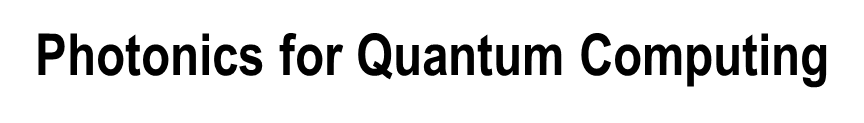

Photonic processors combine sources, mode transformations, entangling resources, detectors, fast feed-forward, and classical control. A hardware claim is meaningful only after the encoding, loss model, success probability, detector assumptions, and error-correction strategy are stated.

### Lasers and coherent states

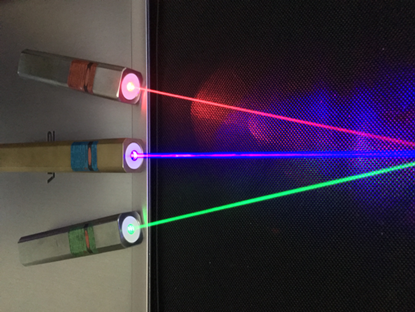

Laser action combines population inversion with stimulated emission to produce directional light with high temporal and spatial coherence. An ideal single optical mode with a stable phase reference is modeled by the coherent state

$$
|\alpha\rangle=e^{-|\alpha|^2/2}\sum_{n=0}^{\infty}
\frac{\alpha^n}{\sqrt{n!}}|n\rangle.
$$

Its Poissonian photon-number fluctuations mean that it is not a deterministic single-photon source. Lasers nevertheless provide pump fields, local oscillators, phase references, and controls.

### Single-photon detectors

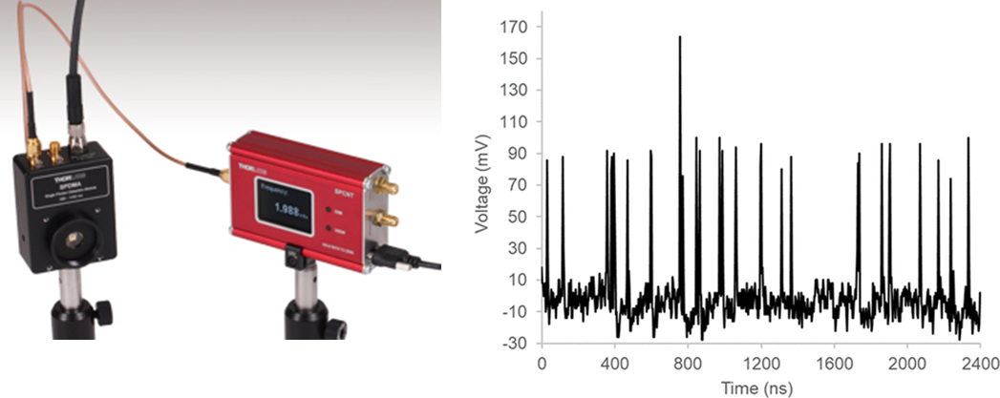

A detector produces a classical event (a click) in response to absorbed light. Important metrics include system detection efficiency, dark-count rate, timing jitter, reset or dead time, maximum count rate, and photon-number resolution. Electrical pulse height is a detector/electronics property; it is not a direct measurement of the incident photon's optical-field amplitude.

### Encoding quantum information in light

Photonic information may be encoded in path, polarization, time bins, frequency bins, photon number, or continuous-variable quadratures. For dual-rail path encoding,

$$|0_L\rangle=|1,0\rangle,\qquad |1_L\rangle=|0,1\rangle,$$

where the entries are occupations of two orthogonal optical modes. A general dual-rail qubit is $\alpha|1,0\rangle+\beta|0,1\rangle$; vacuum and multiphoton components lie outside the logical subspace and represent loss/leakage or source errors. Polarization encoding similarly uses two orthogonal polarization modes.

## Path encoding and beam splitters

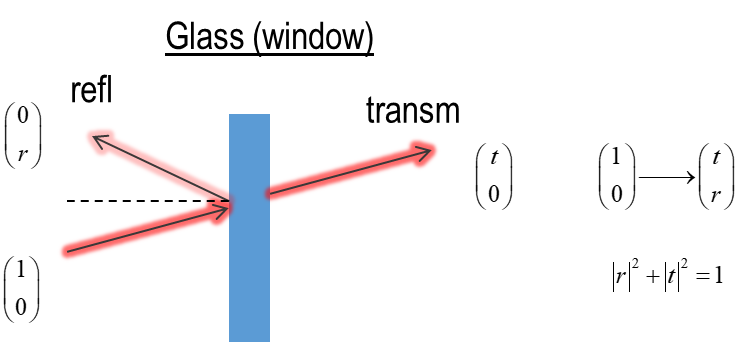

For dual-rail path encoding, $|0_L\rangle=|1,0\rangle$ and $|1_L\rangle=|0,1\rangle$. A lossless beam splitter is a two-mode unitary. Complex reflection and transmission amplitudes obey the full unitarity relations, not only $|r|^2+|t|^2=1$. A balanced beam splitter is Hadamard-like only up to input/output phases, so one phase convention must be used consistently through an interferometer.

### Beam-splitter path labels

Let $|0_L\rangle$ and $|1_L\rangle$ denote one photon in the lower and upper path, respectively. These mode states are orthogonal. Arrow-shaped kets in the course figure are path labels, not polarization vectors.

One common symmetric convention is

$$U_{\mathrm{BS}}=\frac{1}{\sqrt{2}}\begin{pmatrix}1&i\\i&1\end{pmatrix}.$$

Other Hadamard-like conventions are equivalent after consistently redefining port phases.

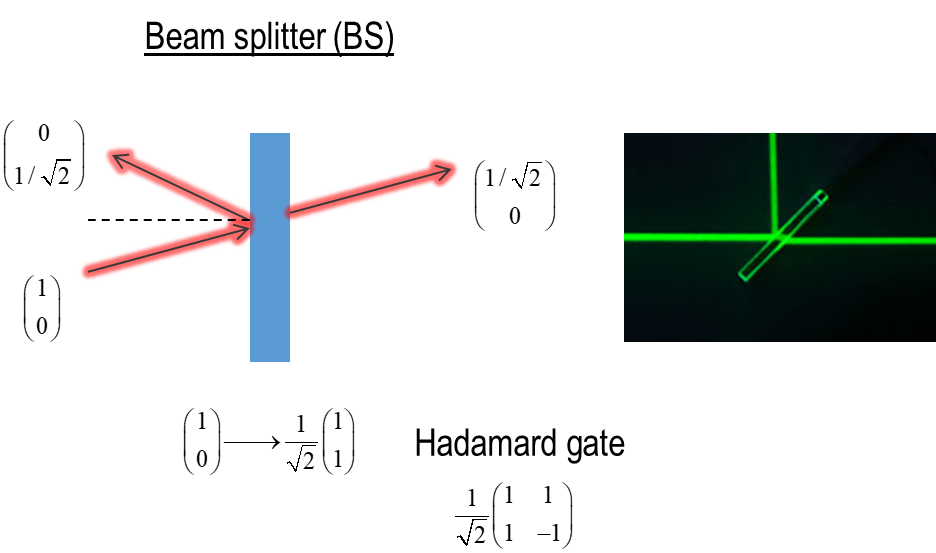

For an ideal balanced Mach–Zehnder interferometer, a suitable phase convention gives output probabilities

$$P_0=\cos^2(\phi/2),\qquad P_1=\sin^2(\phi/2).$$

Which physical port is called 0 may exchange these expressions. Visibility below one indicates distinguishability, phase noise, loss imbalance, or imperfect components.

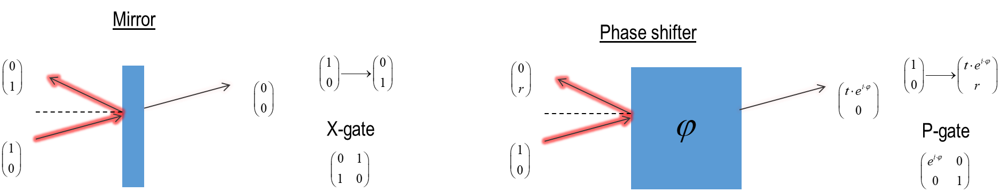

For arms with refractive indices $n_1,n_2$ and physical lengths $L_1,L_2$, the relative propagation phase is

$$
\phi=\frac{2\pi}{\lambda_0}(n_1L_1-n_2L_2)+\phi_{\mathrm{offset}},
$$

where $\lambda_0$ is the vacuum wavelength. The simpler expression $2\pi n\Delta L/\lambda_0$ applies when both arms share one refractive index and $\Delta L=L_1-L_2$.

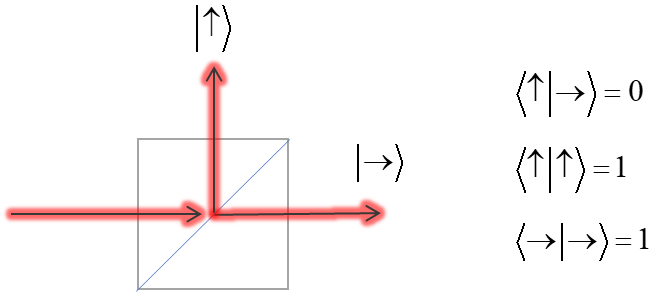

Blocking one arm removes the path coherence needed for deterministic interference. For an ideal balanced interferometer with an ideal absorbing object, the photon is absorbed with probability $1/2$; each output detector then clicks with unconditional probability $1/4$. Conditional on no absorption, the outputs are equally likely.

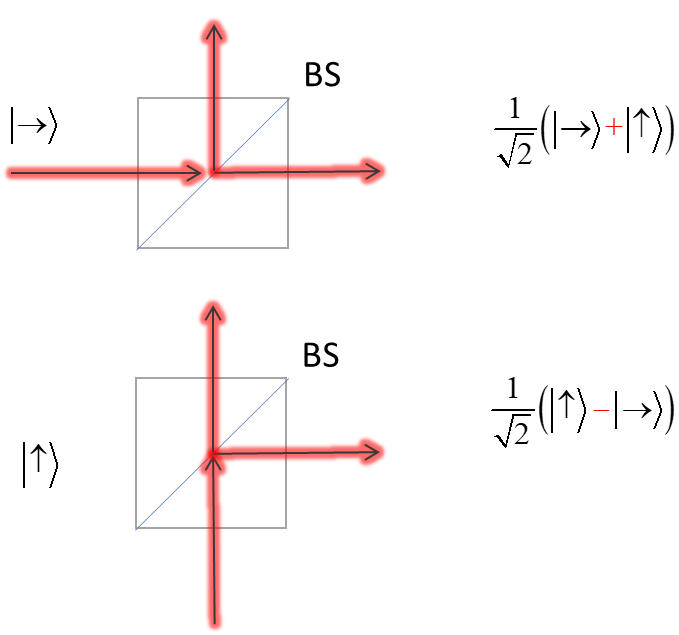

With no which-path information and the phase tuned appropriately, the two amplitudes interfere destructively at one “dark” port and constructively at the other. The ideal 100:0 split assumes indistinguishable paths, stable phase, loss balance, and ideal beam splitters.

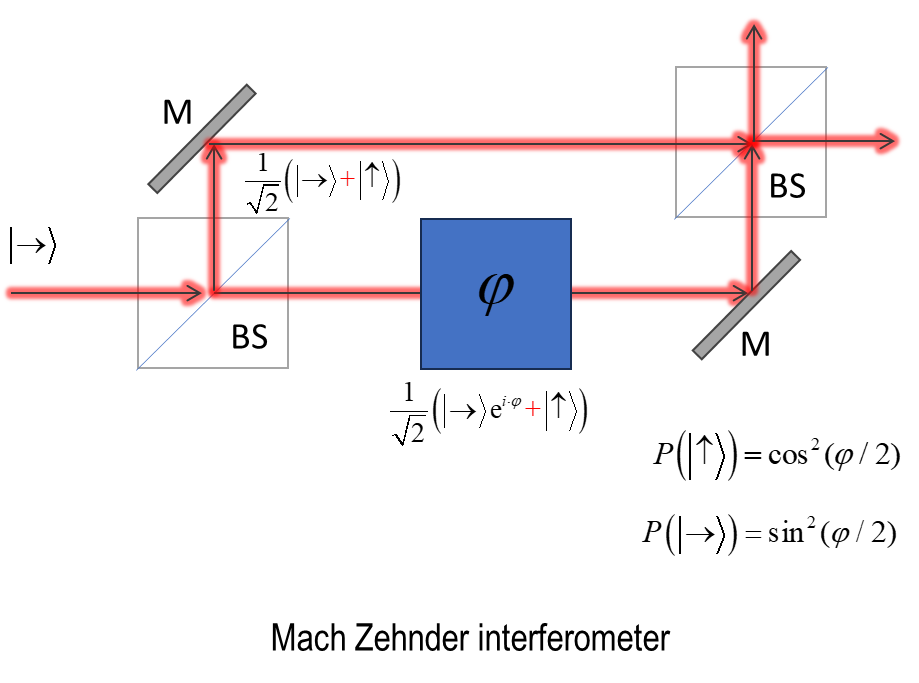

In the ideal single-pass Elitzur–Vaidman scheme, a live absorbing bomb explodes with probability $1/2$, gives an inconclusive bright-port click with probability $1/4$, and gives a dark-port click with probability $1/4$. The dark-port event certifies the object's presence although that detected photon was not absorbed. “Interaction-free” does not mean that every trial avoids interaction, and the basic scheme succeeds conclusively without explosion only one quarter of the time.

Primary source: A. C. Elitzur and L. Vaidman, [*Found. Phys.* **23**, 987–997 (1993)](https://doi.org/10.1007/BF00736012).

## Polarization encoding

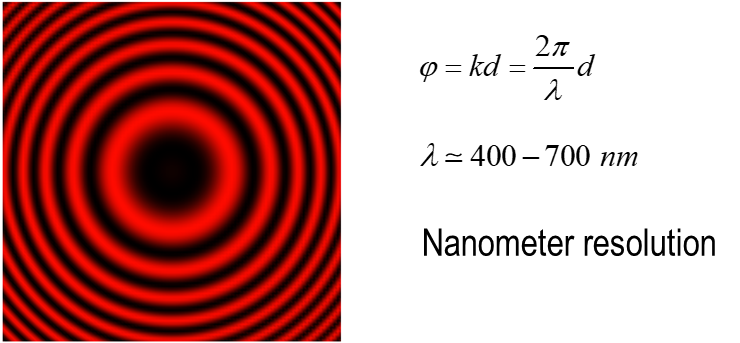

Choose orthogonal modes $|H\rangle$ and $|V\rangle$ as the logical basis. A pure polarization qubit is $\alpha|H\rangle+\beta|V\rangle$ with $|\alpha|^2+|\beta|^2=1$. Spatial mode, spectrum, and arrival time must remain sufficiently indistinguishable when polarization amplitudes interfere.

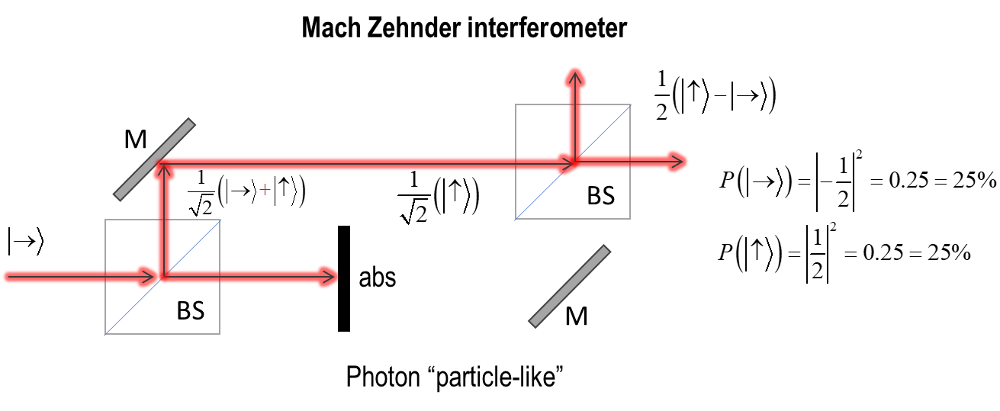

For a plane wave, polarization describes the transverse electric-field mode; the magnetic field is fixed by Maxwell's equations and the propagation direction. A single-photon polarization state is not a tiny classical arrow, although classical Jones vectors and quantum single-photon mode amplitudes obey the same linear transformations.

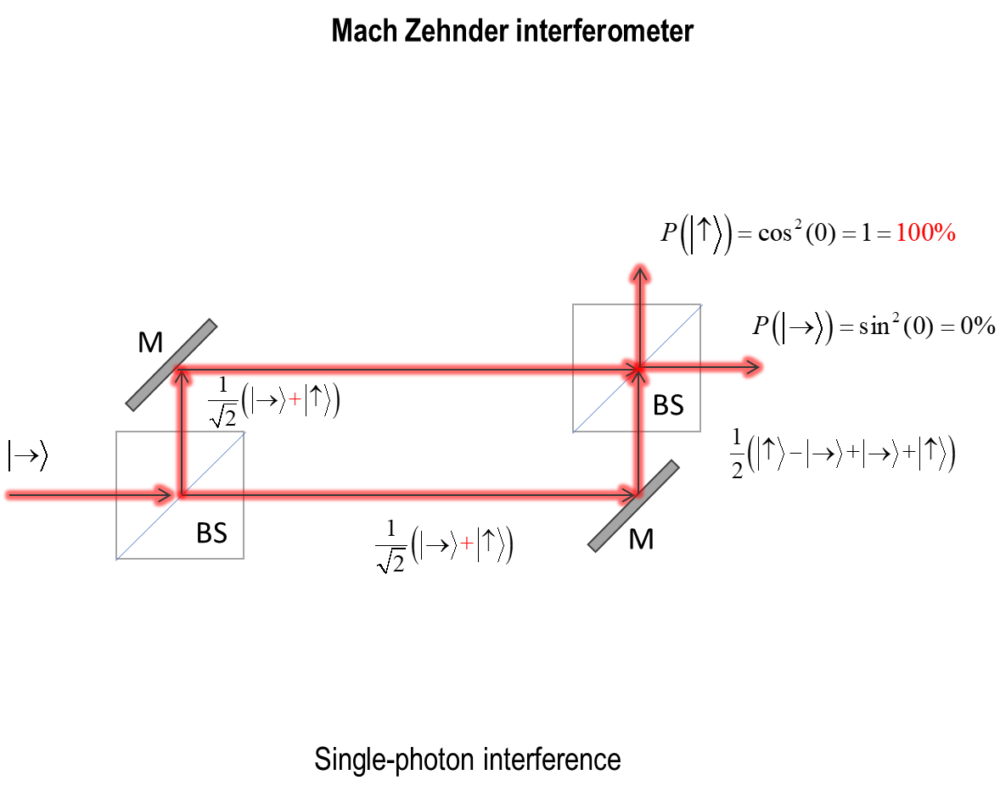

Unpolarized light has polarization density matrix $I/2$. An ideal linear polarizer transmits half its intensity and prepares the transmitted ensemble in its pass-axis polarization. It is a lossy filter, not a unitary qubit gate on every incident photon.

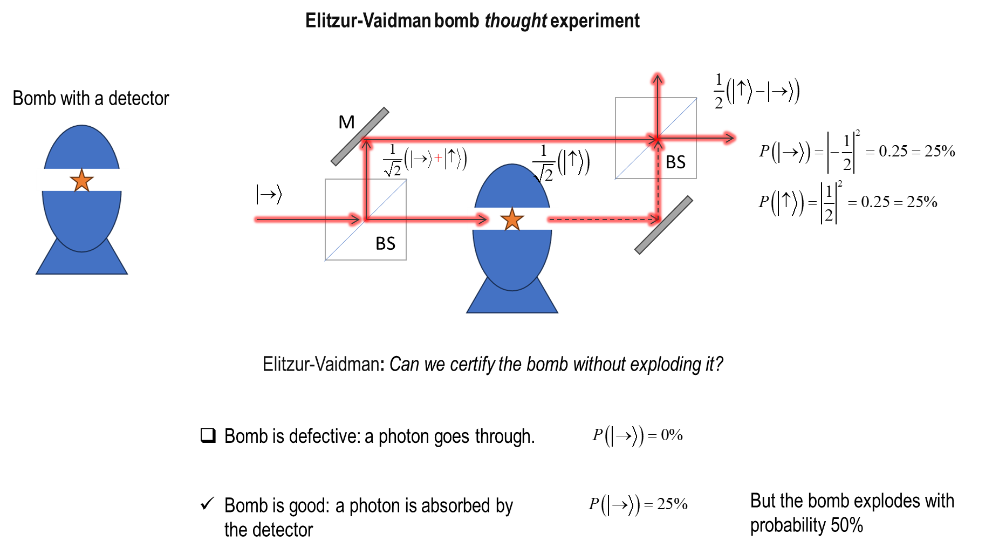

For a photon linearly polarized at angle $\theta$ relative to an ideal analyzer, Malus' law gives transmission probability $\cos^2\theta$. Crossed polarizers ideally block the light; inserting an intermediate polarizer changes the state and can restore nonzero transmission.

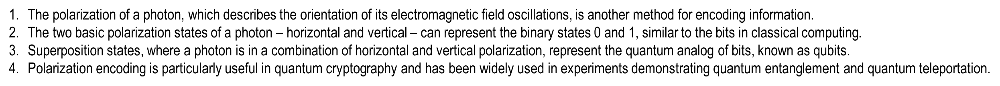

A photon is in a coherent superposition of horizontal and vertical polarization only when such a pure state has been prepared. Unpolarized light is instead represented by the mixed state $I/2$ and should not be described as one photon “in both polarizations.” The probability of passing an analyzer in state $|a\rangle$ is $|\langle a|\psi\rangle|^2$.

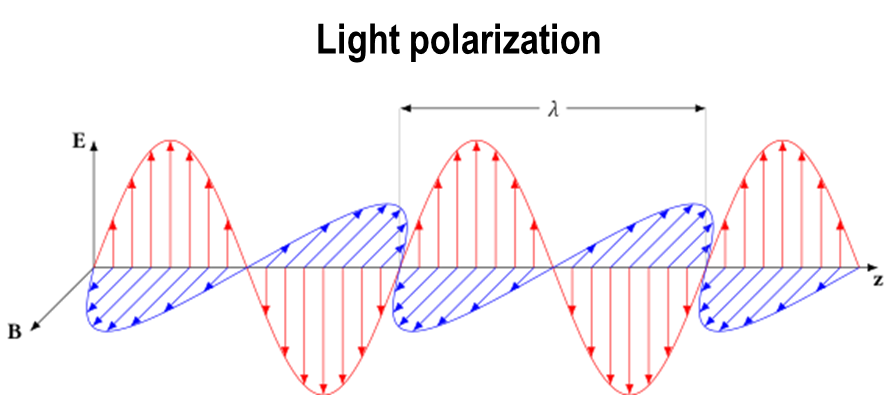

A rotated analyzer performs a basis-dependent, probabilistic projection. Conditioned on transmission, the output is the analyzer's pass-axis state; the discarded outcome and loss probability must be included when assessing a photonic protocol.

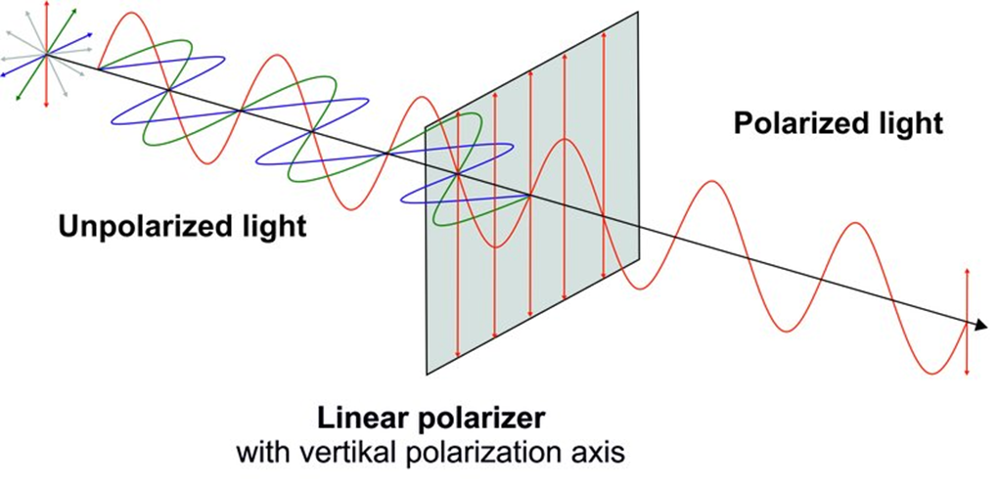

A wave plate introduces a relative phase between its principal axes. Its gate action depends on retardance $\delta$ and optic-axis angle $\theta$:

$$U(\delta,\theta)=R(-\theta)
\begin{pmatrix}e^{-i\delta/2}&0\\0&e^{i\delta/2}\end{pmatrix}R(\theta).$$

In the $H/V$ basis, a half-wave plate at $22.5^\circ$ implements a Hadamard transformation up to phases. A generic wave plate is not simply “the phase gate.”

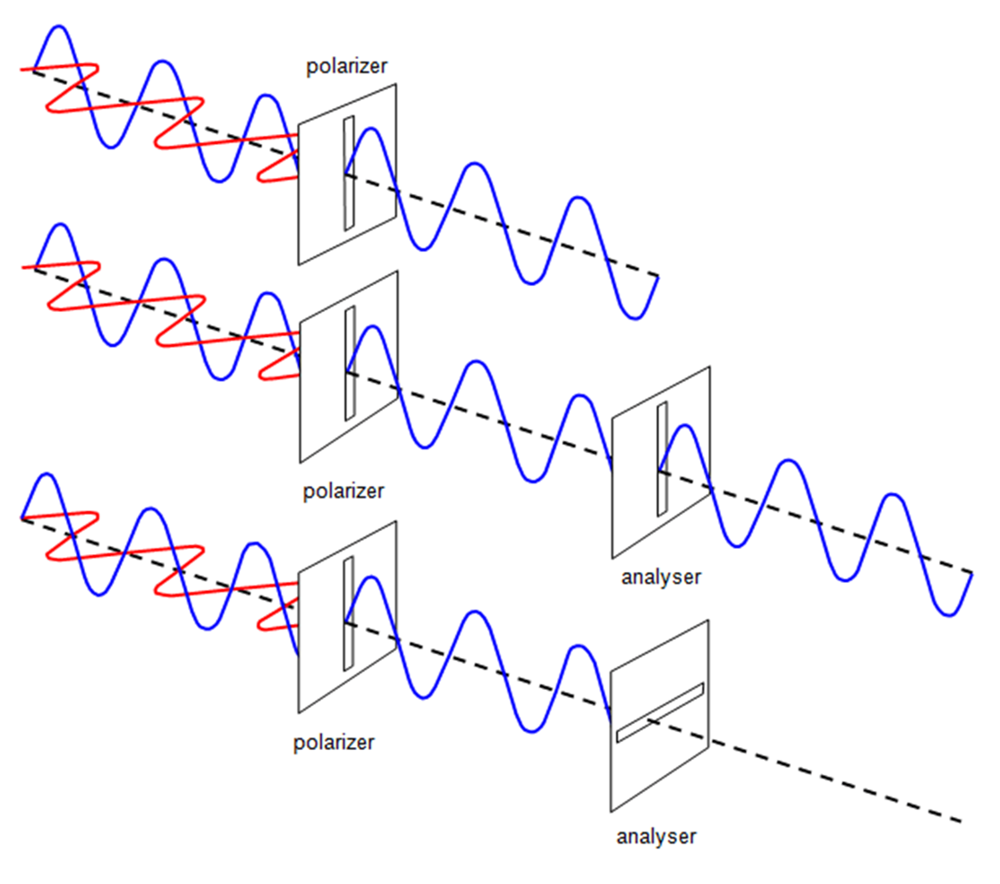

A half-wave plate has retardance $\pi$ and can rotate linear polarization; a quarter-wave plate has retardance $\pi/2$ and can convert suitable linear states to circular states. The precise Jones/unitary matrix depends on axis angle and phase convention.

### Polarization analysis in practice

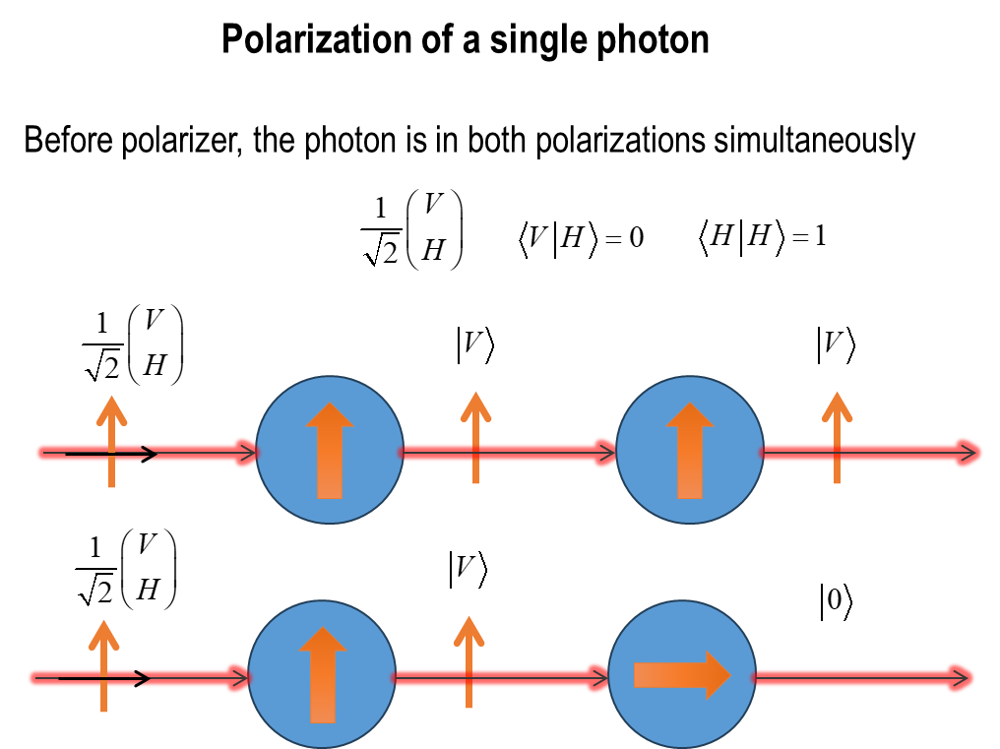

Real analyzers combine wave plates, polarizing beam splitters, and detectors. The reported probability is conditioned on source emission, channel transmission, detector efficiency, and any heralding rule; loss must not be silently discarded when comparing protocols.

## Two-qubit photonic gates

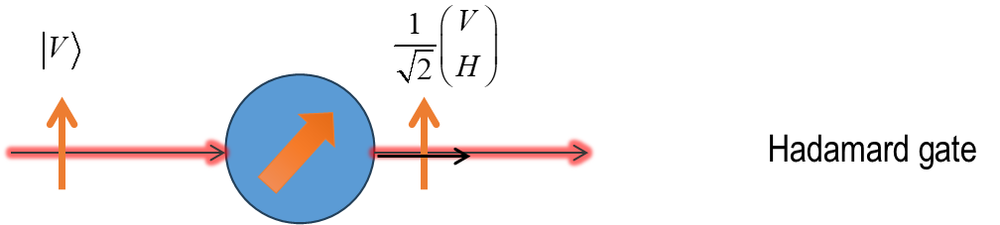

The schematic decomposes a controlled operation using a conditional $\pi$ phase shift. At the single-photon level, the physical resource producing that conditional phase must be specified. Linear-optical entangling gates are generally heralded/probabilistic or consume ancillary resource states, measurements, and feed-forward; success probability and loss must be included.

Source: J. L. O'Brien, [“Optical quantum computing,” *Science* **318**, 1567–1570 (2007)](https://doi.org/10.1126/science.1142892).

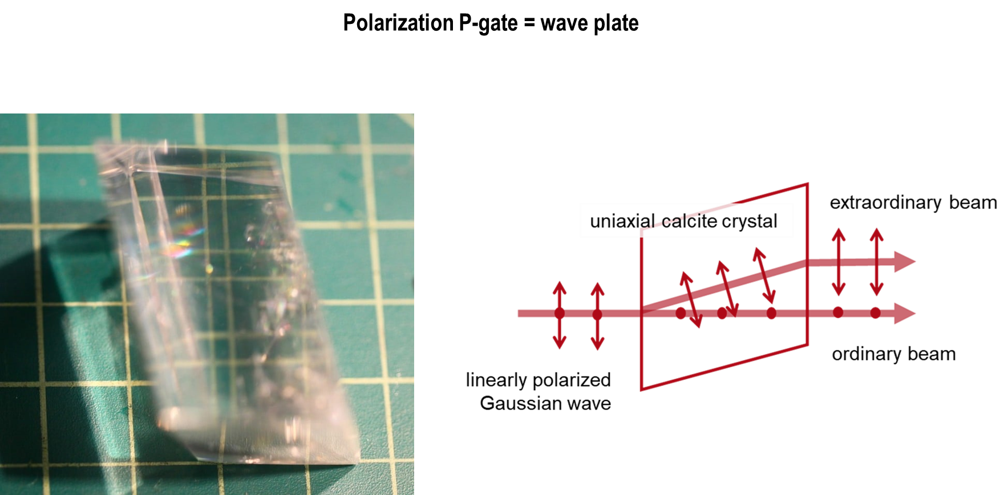

Spontaneous parametric down-conversion probabilistically produces signal–idler photon pairs. Energy and momentum conservation constrain the pair but do not by themselves guarantee a desired entangled state. Entanglement depends on pump state, crystal geometry, phase matching, indistinguishability, filtering, and compensation; weak pumping also leaves a dominant vacuum component and nonzero multipair probability.

Reference: P. G. Kwiat *et al.*, [*Phys. Rev. Lett.* **75**, 4337 (1995)](https://doi.org/10.1103/PhysRevLett.75.4337).

### Wave plates in an experimental layout

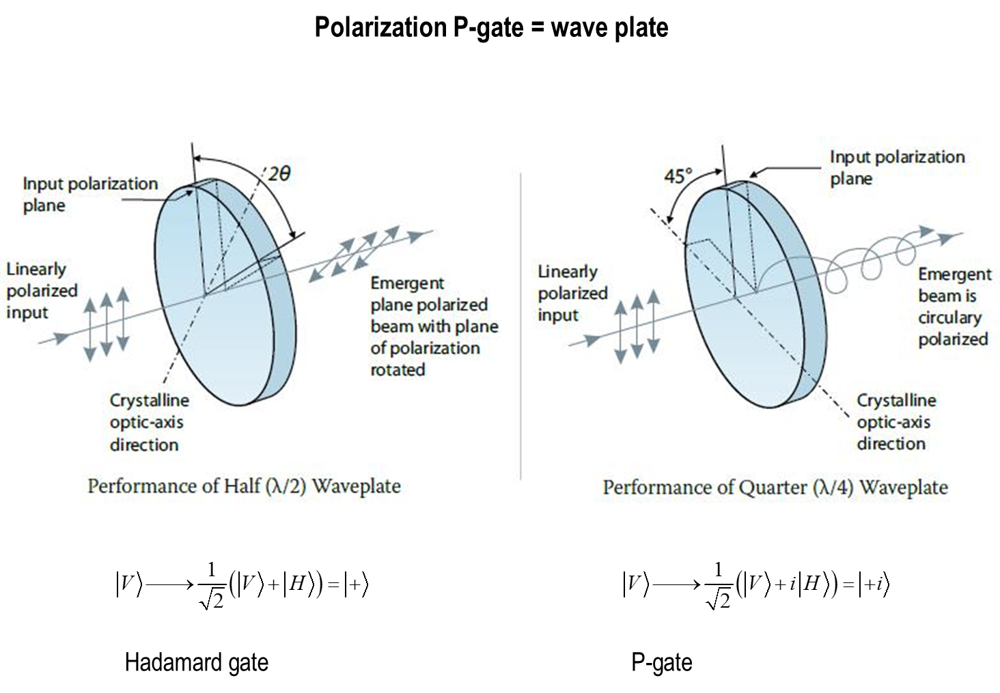

The optic-axis angle sets the rotation basis and the retardance sets the relative phase. Calibration must include wavelength dependence, mounting offsets, and spatial-mode effects; a nominal half- or quarter-wave plate is not an ideal gate over arbitrary bandwidth.

## Scaling photonic systems: source, loss, and feed-forward budgets

Photonic resource estimates must track source brightness and multipair noise, indistinguishability, component insertion loss, detector efficiency, switching depth, heralding probability, multiplexing, and feed-forward latency. Multiplying stage efficiencies makes clear why a larger mode count alone does not establish a larger usable computer.

### Linear-optical entangling resources

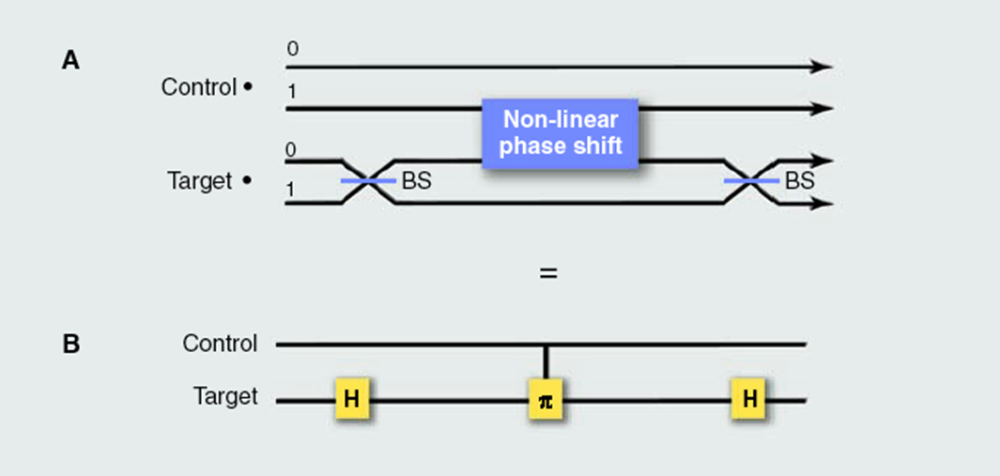

Passive linear optics cannot supply a deterministic interaction between two independently encoded photonic qubits by itself. Measurement-induced gates can be heralded using ancilla photons, detectors, and feed-forward; their success and loss overhead must be included. The KLM construction establishes universality with such resources.

Primary source: E. Knill, R. Laflamme, and G. J. Milburn, [*Nature* **409**, 46-52 (2001)](https://doi.org/10.1038/35051009).

### Pair generation and entanglement qualification

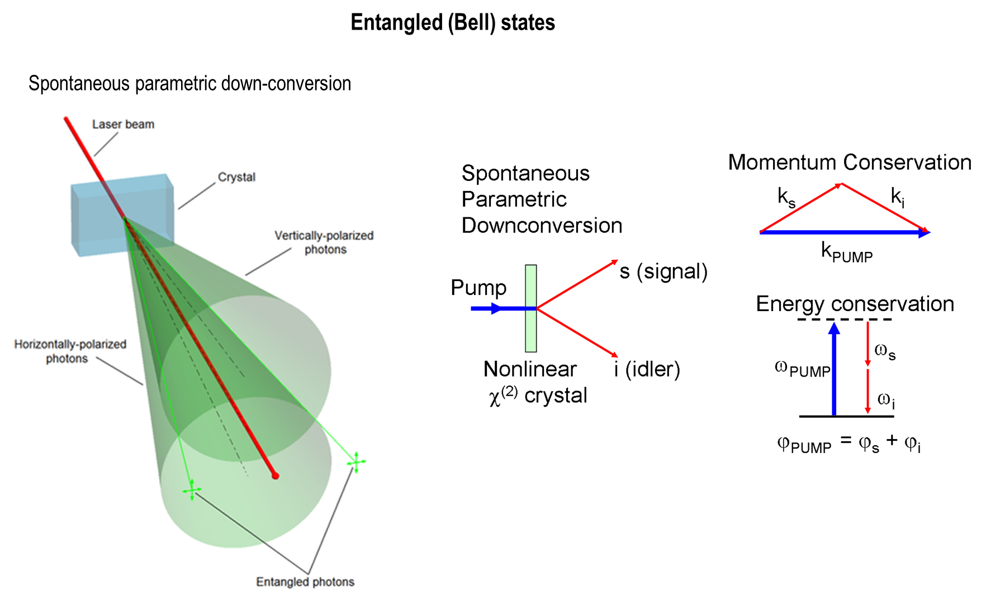

Energy and momentum conservation constrain spontaneous parametric down-conversion, but entanglement also requires coherent alternatives and sufficiently indistinguishable emission. Brightness must be balanced against multipair contamination, and claims should state heralding efficiency, spectral filtering, collection efficiency, and measured state quality.

Primary source: P. G. Kwiat *et al.*, [*Phys. Rev. Lett.* **75**, 4337 (1995)](https://doi.org/10.1103/PhysRevLett.75.4337).

## Gaussian boson sampling as a workload benchmark

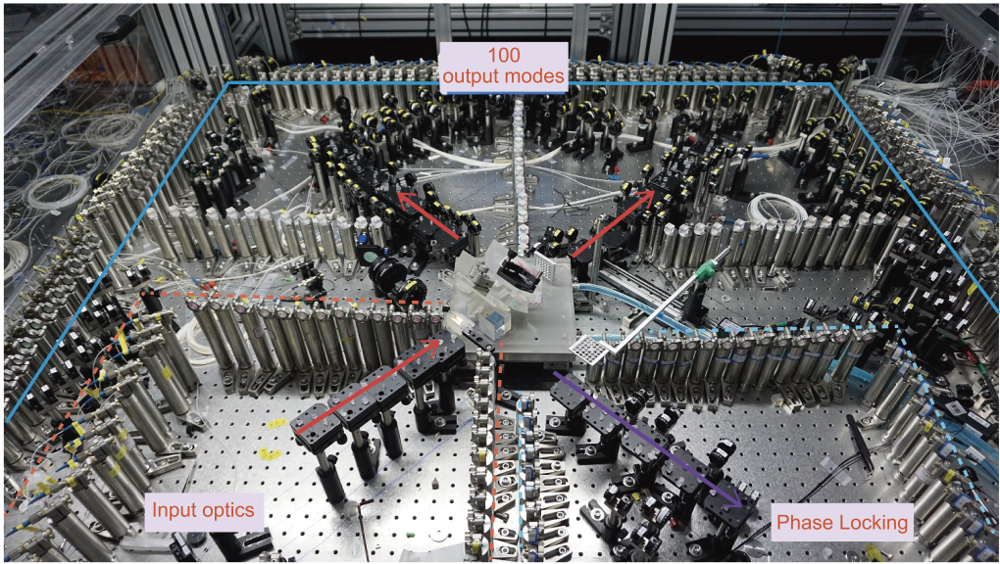

Gaussian boson sampling is a specialized sampling task, not a universal gate-model computation and not a processor with one qubit per detected mode. Experimental advantage claims depend on the stated distribution, validation tests, loss and distinguishability model, and best available classical simulation. Avoid converting a mode or photon count into a fragile general-purpose "qubit count."

Primary source: H.-S. Zhong *et al.*, [*Science* **370**, 1460-1463 (2020)](https://doi.org/10.1126/science.abe8770).

## Integrated photonic circuits

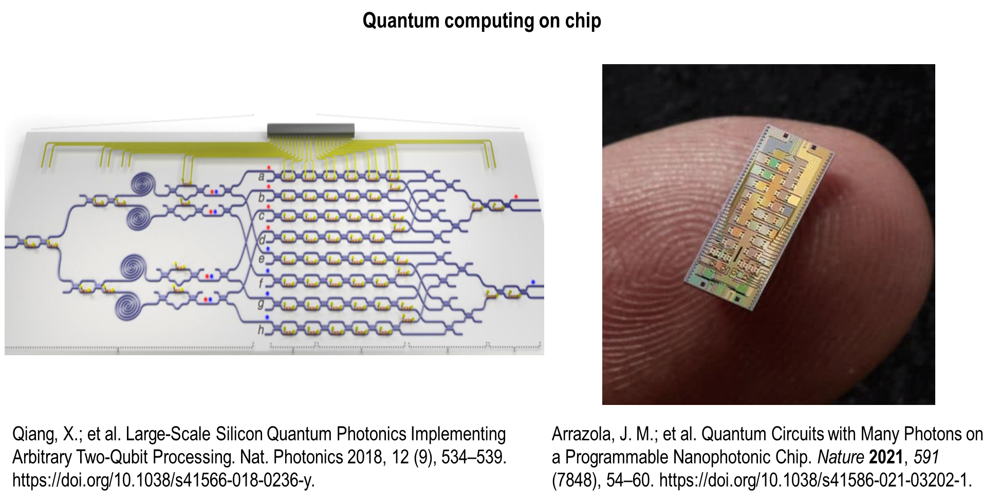

The examples illustrate interferometers, phase shifters, sources, and detectors integrated at increasing scale. Integration reduces alignment burden but does not remove coupling loss, propagation loss, source indistinguishability, detector requirements, calibration, or packaging constraints.

Sources shown in the figure: J. Qiang *et al.*, [*Nature Photonics* **12**, 534–539 (2018)](https://doi.org/10.1038/s41566-018-0236-y); J. M. Arrazola *et al.*, [*Nature* **591**, 54–60 (2021)](https://doi.org/10.1038/s41586-021-03202-1).

## Quantum nanophotonics

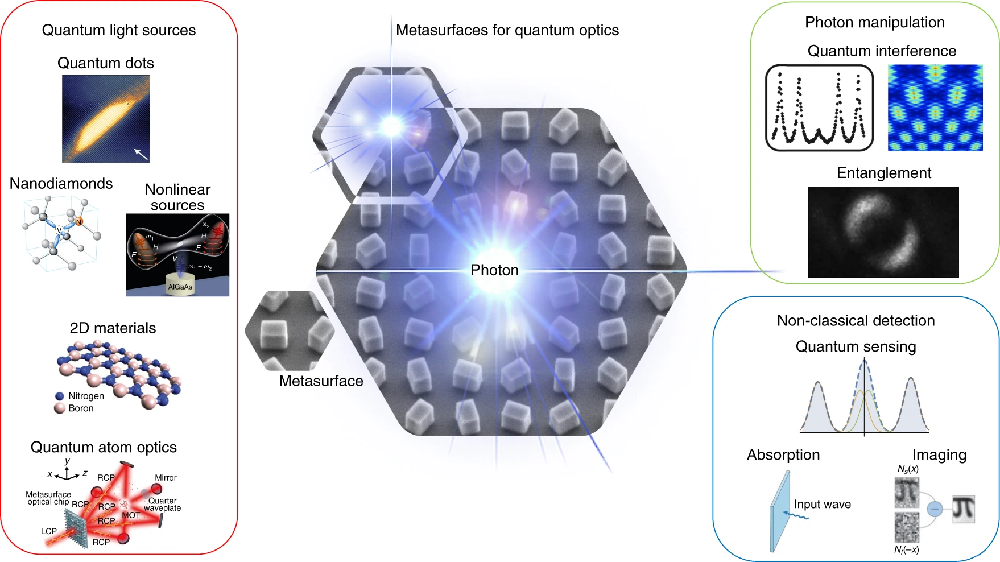

Nanophotonic cavities, waveguides, quantum emitters, nonlinear materials, and metasurfaces can enhance light–matter coupling and compact state preparation or measurement. A component-level demonstration is not by itself a universal processor: scalable computation additionally needs a defined encoding, low-loss interconnects, indistinguishable sources, entangling resources, detection, feed-forward, calibration, and fault-tolerant error management.

## Photonic architecture: balanced assessment

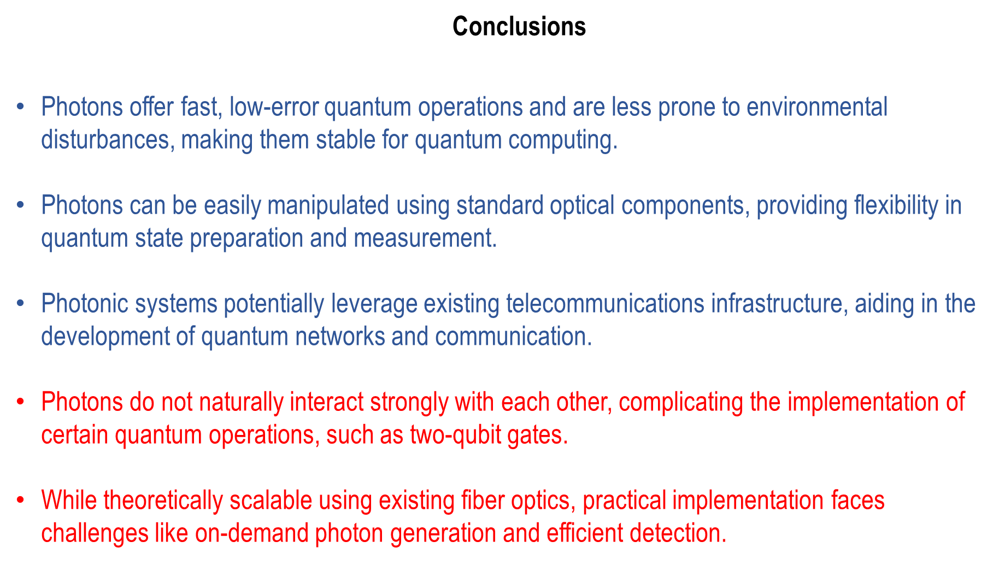

Photons are excellent information carriers and interact weakly with many environments, which supports networking and low-decoherence propagation. These properties do **not** imply universally fast or low-error gates. Loss, source efficiency, indistinguishability, switching, detector performance, feed-forward latency, and resource-state overhead are central constraints. Passive optical circuits may operate at room temperature, while leading superconducting single-photon and photon-number-resolving detectors commonly require cryogenic operation.

## Key takeaways

- A quantum-computer architecture must integrate state preparation, control, measurement, calibration, classical processing, and fault tolerance.
- Benchmarks answer different questions; no single scalar captures component quality, system capability, and application performance.
- Resource estimation connects an algorithm to logical qubits, logical operations, code distance, factories, runtime, and physical hardware.
- Photonic systems are naturally suited to communication and modular links, while scalable computation must manage loss and probabilistic resources explicitly.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. D. P. DiVincenzo, [“The physical implementation of quantum computation”](https://arxiv.org/abs/quant-ph/0002077) (2000).
2. E. Magesan, J. M. Gambetta, and J. Emerson, [randomized benchmarking](https://doi.org/10.1103/PhysRevLett.106.180504), *Phys. Rev. Lett.* **106**, 180504 (2011).
3. A. W. Cross *et al.*, [randomized model circuits and quantum volume](https://doi.org/10.1103/PhysRevA.100.032328), *Phys. Rev. A* **100**, 032328 (2019).
4. A. G. Fowler *et al.*, [surface-code error correction](https://doi.org/10.1103/PhysRevA.86.032324), *Phys. Rev. A* **86**, 032324 (2012).
5. Google Quantum AI and Collaborators, [below-threshold surface-code memories](https://doi.org/10.1038/s41586-024-08449-y), *Nature* **638**, 920–926 (2025), with [2026 author correction](https://doi.org/10.1038/s41586-026-10559-8).
6. C. Monroe *et al.*, [modular architecture with photonic interconnects](https://doi.org/10.1103/PhysRevA.89.022317), *Phys. Rev. A* **89**, 022317 (2014).
7. S. Wehner, D. Elkouss, and R. Hanson, [“Quantum internet: A vision for the road ahead”](https://doi.org/10.1126/science.aam9288), *Science* **362**, eaam9288 (2018).
8. C. Gidney and M. Ekerå, [fault-tolerant factoring resource estimation](https://doi.org/10.22331/q-2021-04-15-433), *Quantum* **5**, 433 (2021).
9. E. Knill, R. Laflamme, and G. J. Milburn, [linear-optical quantum computation](https://doi.org/10.1038/35051009), *Nature* **409**, 46–52 (2001).
10. J. L. O'Brien, [photonic quantum computing](https://doi.org/10.1126/science.1142892), *Science* **318**, 1567–1570 (2007).
11. F. Flamini, N. Spagnolo, and F. Sciarrino, [photonic technologies review](https://doi.org/10.1088/1361-6633/aad5b2), *Rep. Prog. Phys.* **82**, 016001 (2019).
12. L. S. Madsen *et al.*, [Borealis Gaussian boson sampling](https://doi.org/10.1038/s41586-022-04725-x), *Nature* **606**, 75–81 (2022).
13. H.-S. Zhong *et al.*, [Jiuzhang Gaussian boson sampling](https://doi.org/10.1126/science.abe8770), *Science* **370**, 1460–1463 (2020).
14. J. M. Arrazola *et al.*, [programmable photonic circuits](https://doi.org/10.1038/s41586-021-03202-1), *Nature* **591**, 54–60 (2021).